In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_rows', 500)

In [87]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

In [88]:
train_df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


In [89]:
len(train_df), len(train_df.columns), len(test_df), len(test_df.columns)

(1460, 81, 1459, 80)

In [90]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde


def plot_clipped_CDF_and_PDF(data, leftClip=1, rightClip=99, bins=100):
    fig, (ax_cdf, ax_pdf) = plt.subplots(1, 2, figsize=(12, 5))

    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    color_map = {name: colors[i % len(colors)] for i, name in enumerate(data)}

    for name, arr in data.items():
        arr = np.asarray(arr)
        color = color_map[name]

        left_val = np.percentile(arr, leftClip)
        right_val = np.percentile(arr, rightClip)

        x = np.sort(arr)
        y = np.arange(1, len(x) + 1) / len(x) * 100

        mask = (x >= left_val) & (x <= right_val)
        x = x[mask]
        y = y[mask]

        # --- CDF (left subplot) ---
        ax_cdf.plot(x, y, label=name, color=color)

        # --- PDF: histogram + KDE (right subplot) ---
        ax_pdf.hist(x, bins=bins, density=True, alpha=0.3, label=name, color=color)
        kde = gaussian_kde(x)
        x_kde = np.linspace(x.min(), x.max(), 200)
        ax_pdf.plot(x_kde, kde(x_kde), color=color)

    ax_cdf.set(xlabel="Value", ylabel="Cumulative Probability (%)", title="Clipped CDF")
    ax_cdf.legend()

    ax_pdf.set(xlabel="Value", ylabel="Density", title="Clipped PDF (Histogram + KDE)")
    ax_pdf.legend()

    plt.tight_layout()
    plt.show()

def missing_zero_summary(train_df, test_df, cols=None):
    cols = cols if cols is not None else test_df.columns

    def pct_table(df, name):
        missing_pct = df[cols].isnull().mean() * 100
        zero_pct = (df[cols] == 0).mean() * 100
        return pd.DataFrame({
            f'missing%_{name}': missing_pct,
            f'zero%_{name}': zero_pct,
            f'missing_plus_zero%_{name}': missing_pct + zero_pct
        })

    summary = pct_table(train_df, 'train').join(pct_table(test_df, 'test'), how='outer')
    summary = summary[(summary.filter(like='missing_plus_zero%').sum(axis=1)) > 0]  # drop all-zero rows

    return summary.sort_values('missing_plus_zero%_train', ascending=False).reset_index().rename(columns={'index': 'col'})

def check_unseen_categories(train_df, test_df):
    for col in train_df.columns:
        if not train_df[col].dtype.kind in "iufc": 
            train_categories = set(train_df[col].dropna().unique())
            test_categories = set(test_df[col].dropna().unique())

            unseen = test_categories - train_categories
            if unseen:
                print(f"{col}: {sorted(unseen)}")
                
def fill_na_train_test(cols, train_df, test_df):
    train_df = train_df.copy()
    test_df = test_df.copy()

    for col in cols:
        if train_df[col].dtype.kind in "iufc":  # numerical
            fill_value = train_df[col].median()
        else:  # categorical
            fill_value = train_df[col].mode(dropna=True)[0]

        train_df[col] = train_df[col].fillna(fill_value)
        test_df[col] = test_df[col].fillna(fill_value)

    return train_df, test_df


def fill_na_train_test_with_flag(cols, train_df, test_df, flag_suffix="_isna"):
    train_df = train_df.copy()
    test_df = test_df.copy()

    for col in cols:
        if train_df[col].dtype.kind in "iufc":  # numerical
            flag_col = f"{col}{flag_suffix}"
            train_df[flag_col] = train_df[col].isna().astype(int)
            test_df[flag_col] = test_df[col].isna().astype(int)

            fill_value = train_df[col].median()
            train_df[col] = train_df[col].fillna(fill_value)
            test_df[col] = test_df[col].fillna(fill_value)
        else:  # categorical
            train_df[col] = train_df[col].fillna("NA")
            test_df[col] = test_df[col].fillna("NA")

    return train_df, test_df

def summarize_outliers(df, cols, upper_multiplier=1.5):
    rows = []
    for col in cols:
        if not pd.api.types.is_numeric_dtype(df[col]):
            continue

        p25, p50, p75, p90, p95, p99 = df[col].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
        upper = p95 * upper_multiplier
        outliers_pct = (df[col] > upper).mean() * 100

        rows.append({
            "col": col, "25%": p25, "median": p50, "75%": p75,
            "90%": p90, "95%": p95, "99%": p99, "outliers%": outliers_pct
        })

    return pd.DataFrame(rows).sort_values(by="outliers%", ascending=False)

    

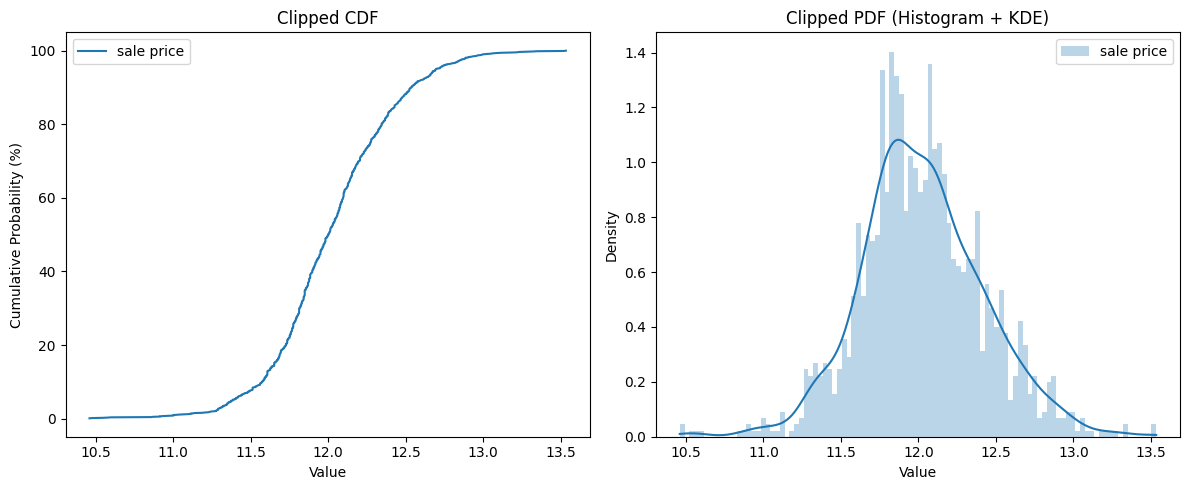

In [91]:
# log transform target sale price
train_df["SalePrice"] = np.log(train_df["SalePrice"])

plot_clipped_CDF_and_PDF({"sale price": train_df["SalePrice"].to_numpy()}, leftClip=0, rightClip=100, bins=100)

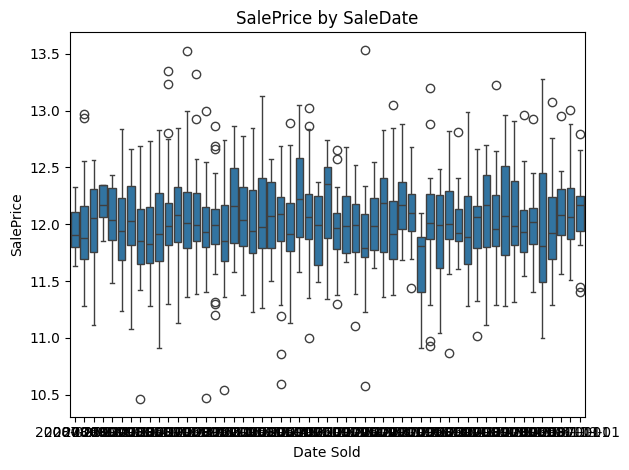

In [92]:
# 1. Create a proper date and aggregate monthly average price per neighborhood
train_df['SaleDate'] = pd.to_datetime(train_df['YrSold'].astype(str) + '-' + train_df['MoSold'].astype(str) + '-01')
test_df['SaleDate'] = pd.to_datetime(test_df['YrSold'].astype(str) + '-' + test_df['MoSold'].astype(str) + '-01')

sns.boxplot(data=train_df, x="SaleDate", y="SalePrice")
plt.title("SalePrice by SaleDate")
plt.xlabel("Date Sold")
plt.ylabel("SalePrice")
plt.tight_layout()
plt.show()

In [93]:
# --- usage ---
summary_df = missing_zero_summary(train_df, test_df)
summary_df

,col,missing%_train,zero%_train,missing_plus_zero%_train,missing%_test,zero%_test,missing_plus_zero%_test
0,PoolArea,0.000000,99.520548,99.520548,0.000000,99.588759,99.588759
1,PoolQC,99.520548,0.000000,99.520548,99.794380,0.000000,99.794380
2,3SsnPorch,0.000000,98.356164,98.356164,0.000000,99.108979,99.108979
3,LowQualFinSF,0.000000,98.219178,98.219178,0.000000,99.040439,99.040439
4,MiscVal,0.000000,96.438356,96.438356,0.000000,96.504455,96.504455
5,MiscFeature,96.301370,0.000000,96.301370,96.504455,0.000000,96.504455
6,BsmtHalfBath,0.000000,94.383562,94.383562,0.137080,93.488691,93.625771
7,Alley,93.767123,0.000000,93.767123,92.666210,0.000000,92.666210
8,ScreenPorch,0.000000,92.054795,92.054795,0.000000,90.404387,90.404387
9,BsmtFinSF2,0.000000,88.561644,88.561644,0.068540,87.594243,87.662783


In [94]:
replace_zero_by_nan_cols = [
    'PoolArea',
    '3SsnPorch',
    'LowQualFinSF',
    'MiscVal',
    'BsmtHalfBath',
    'ScreenPorch',
    'BsmtFinSF2',
    'EnclosedPorch',
    'HalfBath',
    'MasVnrArea',
    'BsmtFullBath',
    '2ndFlrSF',
    'WoodDeckSF',
    'Fireplaces',
    'OpenPorchSF',
    'BsmtFinSF1',
    'BsmtUnfSF',
    'GarageArea',
    'TotalBsmtSF'
]

train_df[replace_zero_by_nan_cols] = train_df[replace_zero_by_nan_cols].replace(0, np.nan)
test_df[replace_zero_by_nan_cols] = test_df[replace_zero_by_nan_cols].replace(0, np.nan)

In [95]:
# check unseen categories

# --- usage ---
check_unseen_categories(train_df, test_df)

In [96]:
# fill missing values in train and test (by train's value)

# --- usage ---
fillna_cols = [
    'Electrical',
    'Exterior1st',
    'Exterior2nd',
    'Functional',
    'GarageCars',
    'KitchenQual',
    'MSZoning',
    'SaleType',
    'Utilities'
]
train_df, test_df = fill_na_train_test(fillna_cols, train_df, test_df)

# --- usage ---
fillna_cols_with_flag = [
    'PoolQC',
    'MiscFeature',
    'Alley',
    'Fence',
    'MasVnrType',
    'FireplaceQu',
    'LotFrontage',
    'GarageFinish',
    'GarageQual',
    'GarageType',
    'GarageYrBlt',
    'GarageCond',
    'BsmtFinType2',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtQual',
    'BsmtCond',
] + replace_zero_by_nan_cols
train_df, test_df = fill_na_train_test_with_flag(fillna_cols_with_flag, train_df, test_df)


In [97]:
# check duplicated row
train_df[train_df.duplicated(subset=['Id'], keep=False)]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,MasVnrArea_isna,BsmtFullBath_isna,2ndFlrSF_isna,WoodDeckSF_isna,Fireplaces_isna,OpenPorchSF_isna,BsmtFinSF1_isna,BsmtUnfSF_isna,GarageArea_isna,TotalBsmtSF_isna


In [98]:
summary_df = missing_zero_summary(train_df, test_df)
summary_df

,col,missing%_train,zero%_train,missing_plus_zero%_train,missing%_test,zero%_test,missing_plus_zero%_test
0,TotalBsmtSF_isna,0.0,97.465753,97.465753,0.0,97.121316,97.121316
1,GarageYrBlt_isna,0.0,94.452055,94.452055,0.0,94.653873,94.653873
2,GarageArea_isna,0.0,94.452055,94.452055,0.0,94.722413,94.722413
3,BsmtUnfSF_isna,0.0,91.917808,91.917808,0.0,91.501028,91.501028
4,LotFrontage_isna,0.0,82.260274,82.260274,0.0,84.441398,84.441398
5,BsmtFinSF1_isna,0.0,68.013699,68.013699,0.0,68.265936,68.265936
6,OpenPorchSF_isna,0.0,55.068493,55.068493,0.0,55.997258,55.997258
7,Fireplaces_isna,0.0,52.739726,52.739726,0.0,49.965730,49.965730
8,WoodDeckSF_isna,0.0,47.876712,47.876712,0.0,47.772447,47.772447
9,2ndFlrSF_isna,0.0,43.219178,43.219178,0.0,42.494859,42.494859


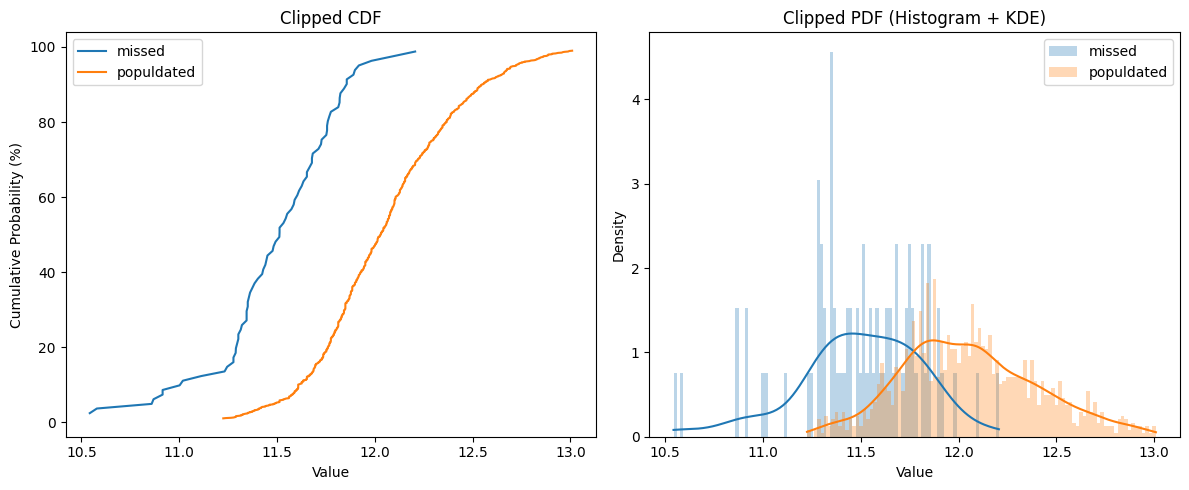

In [99]:
mask = (train_df["GarageType"] == "NA")

plot_clipped_CDF_and_PDF({"missed": train_df[mask]["SalePrice"].to_numpy(), "populdated": train_df[~mask]["SalePrice"].to_numpy()})

In [100]:
# transform year built to age
train_df["Age"] = train_df["YrSold"] - train_df["YearBuilt"]
train_df["AgeRemodAdd"] = train_df["YrSold"] - train_df["YearRemodAdd"]
train_df["GarageAge"] = train_df["YrSold"] - train_df["GarageYrBlt"]

test_df["Age"] = test_df["YrSold"] - test_df["YearBuilt"]
test_df["AgeRemodAdd"] = test_df["YrSold"] - test_df["YearRemodAdd"]
test_df["GarageAge"] = test_df["YrSold"] - test_df["GarageYrBlt"]

# transform square feet columns to log scale
area_cols = [
    "LotArea",
    "MasVnrArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "LowQualFinSF",
    "GrLivArea",
    "GarageArea",
    "WoodDeckSF",
    "OpenPorchSF",
    "EnclosedPorch",
    "3SsnPorch",
    "ScreenPorch",
    "PoolArea"
]
for col in area_cols:
    train_df[col] = np.log(1.0 + train_df[col])
    test_df[col] = np.log(1.0 + test_df[col])

# remove year built columns
train_df = train_df.drop(columns=["YearBuilt", "YearRemodAdd", "GarageYrBlt"])
test_df = test_df.drop(columns=["YearBuilt", "YearRemodAdd", "GarageYrBlt"])

# convert MSSubClass into a categorical feature
train_df["MSSubClass"] = train_df["MSSubClass"].astype("str")
test_df["MSSubClass"] = test_df["MSSubClass"].astype("str")

# remove id column
train_df = train_df.drop(columns=["Id"])
test_df = test_df.drop(columns=["Id"])

# create features
train_df["TotalBath"] = train_df["FullBath"] + 0.5 * train_df["HalfBath"] + train_df["BsmtFullBath"] + 0.5 * train_df["BsmtHalfBath"]
train_df["BathPerBedroom"] = train_df["TotalBath"] / (train_df["BedroomAbvGr"] + 1.0)
train_df["AreaPerRoom"] = train_df["GrLivArea"] / (train_df["TotRmsAbvGrd"] + 1.0)

test_df["TotalBath"] = test_df["FullBath"] + 0.5 * test_df["HalfBath"] + test_df["BsmtFullBath"] + 0.5 * test_df["BsmtHalfBath"]
test_df["BathPerBedroom"] = test_df["TotalBath"] / (test_df["BedroomAbvGr"] + 1.0)
test_df["AreaPerRoom"] = test_df["GrLivArea"] / (test_df["TotRmsAbvGrd"] + 1.0)


In [101]:
# # add training 6 months sales price

# def fit_trailing_avg_price(train_df, window=6):
#     """Compute trailing N-month avg SalePrice per neighborhood, learned from train only."""
#     monthly_avg = (train_df.groupby(['Neighborhood', 'SaleDate'])['SalePrice']
#                    .mean()
#                    .reset_index()
#                    .sort_values(['Neighborhood', 'SaleDate']))

#     def fill_monthly_gaps(g):
#         full_range = pd.date_range(g['SaleDate'].min(), g['SaleDate'].max(), freq='MS')
#         g = g.set_index('SaleDate').reindex(full_range)
#         g['Neighborhood'] = g['Neighborhood'].ffill().bfill()
#         return g.rename_axis('SaleDate').reset_index()

#     monthly_avg = monthly_avg.groupby('Neighborhood', group_keys=False).apply(fill_monthly_gaps)

#     monthly_avg['trailing_avg_price'] = (
#         monthly_avg.groupby('Neighborhood')['SalePrice']
#         .transform(lambda s: s.shift(1).rolling(window=window, min_periods=1).mean())
#     )

#     return monthly_avg[['Neighborhood', 'SaleDate', 'trailing_avg_price']].sort_values(['Neighborhood', 'SaleDate'])


# def apply_trailing_avg_price(df, lookup_table):
#     """Merge trailing avg onto df (train or test) using as-of (most recent prior) match per neighborhood."""
#     merged = pd.merge_asof(
#         df.sort_values('SaleDate'),
#         lookup_table.sort_values('SaleDate'),
#         on='SaleDate',
#         by='Neighborhood',
#         direction='backward'
#     )
#     return merged.sort_index()
# lookup_table = fit_trailing_avg_price(train_df, window=6)

# train_df = apply_trailing_avg_price(train_df, lookup_table)
# test_df = apply_trailing_avg_price(test_df, lookup_table)

In [102]:
# --- usage ---
outliersDf = summarize_outliers(train_df, area_cols)
outliersDf

,col,25%,median,75%,90%,95%,99%,outliers%
0,LotArea,8.929898,9.156887,9.358976,9.573780,9.764349,10.533348,0.0
9,GrLivArea,7.030415,7.289611,7.483104,7.677539,7.810799,8.047013,0.0
15,ScreenPorch,5.198497,5.198497,5.198497,5.198497,5.198497,5.594856,0.0
14,3SsnPorch,5.198497,5.198497,5.198497,5.198497,5.198497,5.198497,0.0
13,EnclosedPorch,4.980176,4.980176,4.980176,4.980176,5.199319,5.568491,0.0
12,OpenPorchSF,4.056095,4.158883,4.234107,4.875197,5.170767,5.658849,0.0
11,WoodDeckSF,5.147494,5.147494,5.147494,5.572154,5.817111,6.227428,0.0
10,GarageArea,5.968067,6.184149,6.357842,6.630815,6.746529,6.911495,0.0
8,LowQualFinSF,5.936216,5.936216,5.936216,5.936216,5.936216,5.936216,0.0
1,MasVnrArea,5.318120,5.318120,5.318120,5.817111,6.124683,6.674903,0.0




In [103]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_feature_distributions(train_df, test_df=None, cols=None, num_cols=4):
    cols = cols if cols is not None else test_df.columns
    num_rows = (len(cols) + num_cols - 1) // num_cols

    fig, axes = plt.subplots(num_rows, num_cols, figsize=(18, num_rows * 4))
    axes = axes.flatten()

    for i, col in enumerate(cols):
        ax = axes[i]
        if pd.api.types.is_numeric_dtype(train_df[col]):
            train_df[col].hist(ax=ax, bins=20, color='skyblue', edgecolor='black', alpha=0.6, density=bool(test_df is not None), label='train')
            if test_df is not None:
                test_df[col].hist(ax=ax, bins=20, color='orange', edgecolor='black', alpha=0.5, density=True, label='test')
                ax.legend(fontsize=8)
        else:
            train_df[col].value_counts(normalize=test_df is not None).plot(
                kind='bar', ax=ax, color='salmon', edgecolor='black', alpha=0.6, label='train'
            )
            if test_df is not None:
                test_df[col].value_counts(normalize=True).reindex(train_df[col].value_counts().index).plot(
                    kind='bar', ax=ax, color='steelblue', edgecolor='black', alpha=0.5, label='test'
                )
                ax.legend(fontsize=8)

        ax.set_title(f'Distribution of {col}')
        ax.tick_params(axis='x', rotation=45)

    for j in range(len(cols), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


# --- usage ---
# plot_feature_distributions(train_df)                       # train only
plot_feature_distributions(train_df, test_df=test_df)       # train vs test overlay

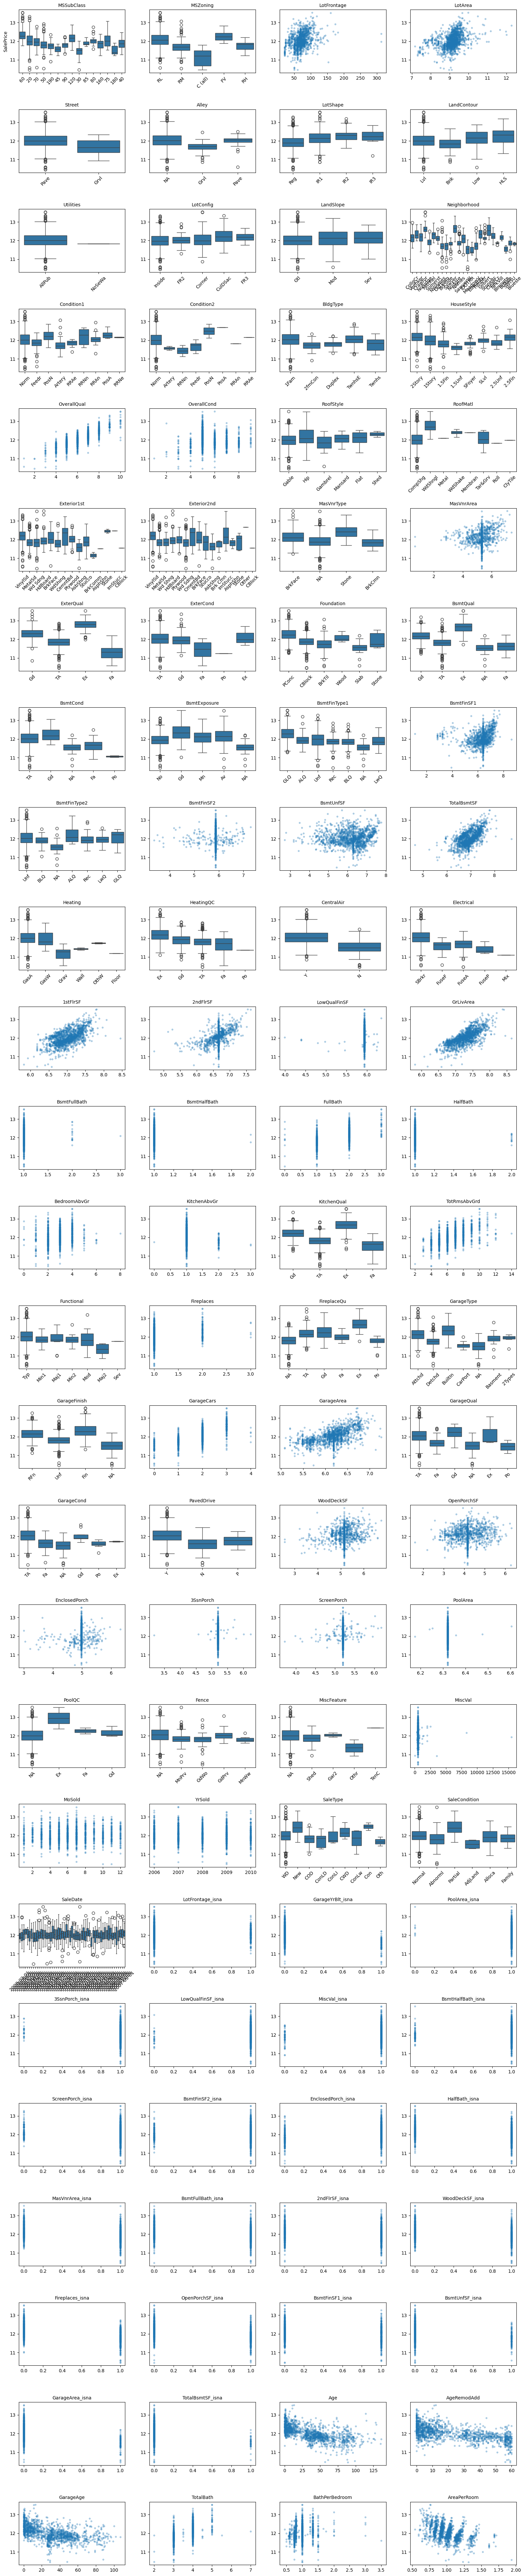

In [104]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_features_vs_target(train_df, target_col, n_cols=3, figsize_per_plot=(4, 3)):
    feature_cols = [c for c in train_df.columns if c != target_col]
    n_rows = int(np.ceil(len(feature_cols) / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols,
                              figsize=(figsize_per_plot[0]*n_cols, figsize_per_plot[1]*n_rows))
    axes = np.array(axes).flatten()

    for ax, col in zip(axes, feature_cols):
        if train_df[col].dtype.kind in "iufc":  # numeric
            ax.scatter(train_df[col], train_df[target_col], alpha=0.3, s=10)
        else:  # categorical
            sns.boxplot(x=train_df[col], y=train_df[target_col], ax=ax)
            ax.tick_params(axis='x', rotation=45)

        ax.set_title(col, fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel(target_col if col == feature_cols[0] else "")

    # hide unused subplots
    for ax in axes[len(feature_cols):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

plot_features_vs_target(train_df, target_col="SalePrice", n_cols=4)

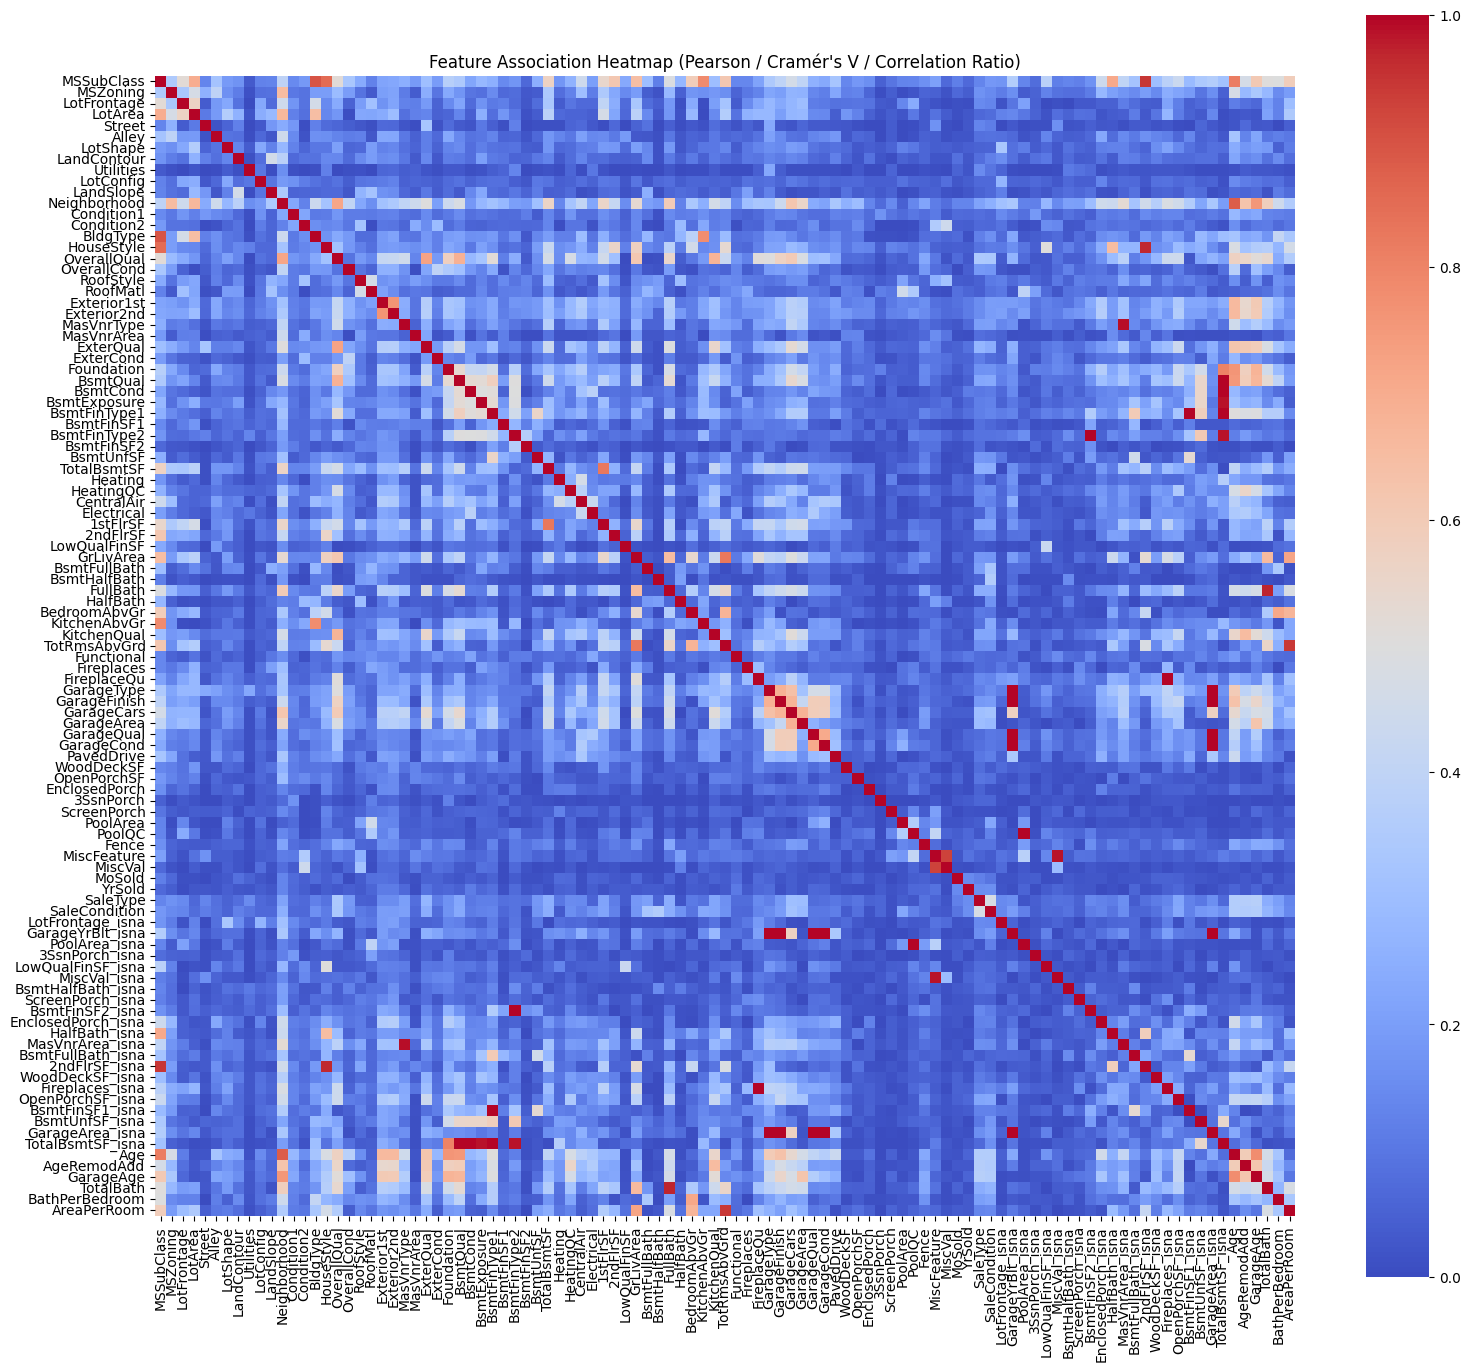

In [105]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats.contingency import association

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    return association(ct, method='cramer')

def correlation_ratio(categories, values):
    df = pd.DataFrame({'cat': categories, 'val': values}).dropna()
    overall_mean = df['val'].mean()
    numerator = df.groupby('cat')['val'].apply(lambda g: len(g) * (g.mean() - overall_mean)**2).sum()
    denominator = ((df['val'] - overall_mean)**2).sum()
    return np.sqrt(numerator / denominator) if denominator > 0 else 0

def pairwise_association(df, col1, col2):
    is_num1 = df[col1].dtype.kind in "iufc"
    is_num2 = df[col2].dtype.kind in "iufc"

    if is_num1 and is_num2:
        return abs(df[col1].corr(df[col2]))
    elif not is_num1 and not is_num2:
        return cramers_v(df[col1], df[col2])
    else:
        cat_col, num_col = (col1, col2) if not is_num1 else (col2, col1)
        return correlation_ratio(df[cat_col], df[num_col])

def mixed_association_matrix(df, cols):
    is_num = df[cols].apply(lambda s: s.dtype.kind in "iufc")
    n = len(cols)
    mat = pd.DataFrame(np.eye(n), index=cols, columns=cols)

    for i in range(n):
        for j in range(i+1, n):
            c1, c2 = cols[i], cols[j]
            val = pairwise_association(df, c1, c2)
            mat.loc[c1, c2] = mat.loc[c2, c1] = abs(val)

    return mat

# --- usage ---
ignore_cols = ["SalePrice", "SaleDate"]
feature_cols = [c for c in train_df.columns if c not in ignore_cols]  # or include target too
assoc_matrix = mixed_association_matrix(train_df, feature_cols)

plt.figure(figsize=(16, 14))
sns.heatmap(assoc_matrix, cmap='coolwarm', vmin=0, vmax=1, square=True,
            xticklabels=True, yticklabels=True)
plt.title("Feature Association Heatmap (Pearson / Cramér's V / Correlation Ratio)")
plt.tight_layout()
plt.show()

In [106]:
import numpy as np
import pandas as pd
from scipy.stats.contingency import association

def drop_correlated_features_target_aware(df, cols, target, threshold=0.9):
    # association of each feature with the target (numeric or categorical target both handled)
    target_assoc = {c: pairwise_association(df, c, target) for c in cols}

    to_drop = set()
    for i, col_i in enumerate(cols):
        if col_i in to_drop:
            continue
        for col_j in cols[i+1:]:
            if col_j in to_drop:
                continue
            assoc = pairwise_association(df, col_i, col_j)
            if assoc > threshold:
                weaker = col_i if target_assoc[col_i] < target_assoc[col_j] else col_j
                to_drop.add(weaker)

                print(f"dropped {weaker} from ({col_i}, {col_j}) with corr = {assoc:.2f}, target_assoc[{col_i}] = {target_assoc[col_i]:.2f}, target_assoc[{col_j}] = {target_assoc[col_j]:.2f}")

    return [c for c in cols if c not in to_drop]

kept_features = drop_correlated_features_target_aware(train_df, feature_cols, target='SalePrice', threshold=0.9)

dropped 2ndFlrSF_isna from (MSSubClass, 2ndFlrSF_isna) with corr = 0.95, target_assoc[MSSubClass] = 0.57, target_assoc[2ndFlrSF_isna] = 0.15
dropped MasVnrArea_isna from (MasVnrType, MasVnrArea_isna) with corr = 0.99, target_assoc[MasVnrType] = 0.43, target_assoc[MasVnrArea_isna] = 0.38
dropped TotalBsmtSF_isna from (BsmtQual, TotalBsmtSF_isna) with corr = 1.00, target_assoc[BsmtQual] = 0.67, target_assoc[TotalBsmtSF_isna] = 0.20
dropped BsmtFinSF1_isna from (BsmtFinType1, BsmtFinSF1_isna) with corr = 1.00, target_assoc[BsmtFinType1] = 0.48, target_assoc[BsmtFinSF1_isna] = 0.16
dropped BsmtFinSF2_isna from (BsmtFinType2, BsmtFinSF2_isna) with corr = 1.00, target_assoc[BsmtFinType2] = 0.21, target_assoc[BsmtFinSF2_isna] = 0.03
dropped TotalBath from (FullBath, TotalBath) with corr = 0.97, target_assoc[FullBath] = 0.59, target_assoc[TotalBath] = 0.59
dropped AreaPerRoom from (TotRmsAbvGrd, AreaPerRoom) with corr = 0.94, target_assoc[TotRmsAbvGrd] = 0.53, target_assoc[AreaPerRoom] = 0.45


In [107]:
import numpy as np
import pandas as pd
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score


def purged_embargo_splits(dates, n_splits=5, embargo=1):
    """Yield (train_idx, val_idx) for expanding-window time series CV with purge/embargo (in months)."""
    months = dates.sort_values().unique()
    fold_bounds = np.array_split(months, n_splits)

    for i in range(1, n_splits):  # first fold has no history to train on
        val_months = fold_bounds[i]
        val_start = val_months.min()

        embargo_mask = val_start - pd.DateOffset(months=embargo)

        train_mask = dates <= embargo_mask
        val_mask = dates.isin(val_months)

        yield np.where(train_mask)[0], np.where(val_mask)[0]


def encode_fold(X_train, X_val, num_cols, cat_cols):
    # one-hot encode categoricals, fit columns on train, align val to same columns
    train_dum = pd.get_dummies(X_train[cat_cols], drop_first=True)
    val_dum = pd.get_dummies(X_val[cat_cols], drop_first=True)
    val_dum = val_dum.reindex(columns=train_dum.columns, fill_value=0)

    # standardize numerics, fit on train only
    scaler = StandardScaler().fit(X_train[num_cols])
    train_num = pd.DataFrame(scaler.transform(X_train[num_cols]), columns=num_cols, index=X_train.index)
    val_num = pd.DataFrame(scaler.transform(X_val[num_cols]), columns=num_cols, index=X_val.index)

    X_train_enc = pd.concat([train_num, train_dum], axis=1)
    X_val_enc = pd.concat([val_num, val_dum], axis=1)
    return X_train_enc, X_val_enc


def cross_validate_elasticnet(df, target_col, num_cols, cat_cols, date_col,
                                alphas, l1_ratios, n_splits=5, embargo=1):
    dates = df[date_col]
    results = []

    for alpha in alphas:
        for l1_ratio in l1_ratios:
            fold_metrics = []
            for train_idx, val_idx in purged_embargo_splits(dates, n_splits, embargo):
                if len(train_idx) == 0 or len(val_idx) == 0:
                    continue
                X_train, X_val = df.iloc[train_idx], df.iloc[val_idx]
                y_train, y_val = df[target_col].iloc[train_idx], df[target_col].iloc[val_idx]

                X_train_enc, X_val_enc = encode_fold(X_train, X_val, num_cols, cat_cols)

                model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=10000)
                model.fit(X_train_enc, y_train)
                preds = model.predict(X_val_enc)

                fold_metrics.append({
                    'rmse': root_mean_squared_error(y_val, preds),
                    'mae': mean_absolute_error(y_val, preds),
                    'r2': r2_score(y_val, preds),
                })

            fold_df = pd.DataFrame(fold_metrics)
            results.append({
                'alpha': alpha,
                'l1_ratio': l1_ratio,
                'rmse': fold_df['rmse'].mean(),
                'mae': fold_df['mae'].mean(),
                'r2': fold_df['r2'].mean(),
            })

    return pd.DataFrame(results).sort_values('rmse')



In [108]:

# --- usage ---
num_cols = [c for c in kept_features if train_df[c].dtype.kind in "iufc"]
cat_cols = [c for c in kept_features if c not in num_cols]
alphas = [0.001, 0.01, 0.1, 1, 10] # overall penalty strength
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 1.0]  # 1.0 = pure L1 (Lasso), 0.0 = pure L2 (Ridge)

cv_results = cross_validate_elasticnet(
    train_df, target_col='SalePrice', num_cols=num_cols, cat_cols=cat_cols,
    date_col='SaleDate', alphas=alphas, l1_ratios=l1_ratios,
    n_splits=10, embargo=1
)
best_params = cv_results.iloc[0]
print(best_params)

alpha       0.010000
l1_ratio    0.100000
rmse        0.136591
mae         0.087769
r2          0.880058
Name: 6, dtype: float64


In [109]:
import pandas as pd
import statsmodels.api as sm
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score


def fit_final_model(df, target_col, num_cols, cat_cols, best_alpha, best_l1_ratio):
    # --- encode full train set ---
    dummies = pd.get_dummies(df[cat_cols], drop_first=True)
    scaler = StandardScaler().fit(df[num_cols])
    num_scaled = pd.DataFrame(scaler.transform(df[num_cols]), columns=num_cols, index=df.index)

    X = pd.concat([num_scaled, dummies], axis=1).astype(float)
    y = df[target_col].astype(float)

    # === PRODUCTION MODEL: ElasticNet with CV-tuned hyperparameters, fit on full train ===
    prod_model = ElasticNet(alpha=best_alpha, l1_ratio=best_l1_ratio, max_iter=10000)
    prod_model.fit(X, y)

    coef_series = pd.Series(prod_model.coef_, index=X.columns)
    selected_features = coef_series[coef_series != 0].index.tolist()
    print(f"Selected {len(selected_features)} / {X.shape[1]} features")

    preds = prod_model.predict(X)
    prod_metrics = {  # in-sample, optimistic — for reference only
        'rmse': root_mean_squared_error(y, preds),
        'mae': mean_absolute_error(y, preds),
        'r2': r2_score(y, preds),
    }

    # === INTERPRETATION-ONLY MODEL: OLS refit on selected features ===
    X_selected = sm.add_constant(X[selected_features])
    ols_model = sm.OLS(y, X_selected).fit()

    return {
        'prod_model': prod_model,
        'prod_metrics': prod_metrics,       # in-sample, optimistic
        'ols_model': ols_model,
        'scaler': scaler,
        'selected_features': selected_features,
        'coefficients': coef_series[coef_series != 0].sort_values(key=abs, ascending=False),
        'X_columns': X.columns.tolist()
    }


In [110]:
# --- usage ---
result = fit_final_model(
    train_df, target_col='SalePrice', num_cols=num_cols, cat_cols=cat_cols,
    best_alpha=best_params['alpha'], best_l1_ratio=best_params['l1_ratio']
)

print("In-sample (optimistic):", result['prod_metrics'])

Selected 98 / 283 features
In-sample (optimistic): {'rmse': 0.11562291596105774, 'mae': 0.076064583890758, 'r2': 0.9161589929341879}


In [111]:
result['ols_model'].summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              SalePrice   R-squared:                       0.925
Model:                            OLS   Adj. R-squared:                  0.919
Method:                 Least Squares   F-statistic:                     174.1
Date:                Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:32:00   Log-Likelihood:                 1155.7
No. Observations:                1460   AIC:                            -2117.
Df Residuals:                    1363   BIC:                            -1605.
Df Model:                          96                                         
Covariance Type:            nonrobust                                         
=========================================================================================
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    11.7017      0.044    268.150      0.000      11.616      11.787
LotFrontage              -0.0067      0.004     -1.616      0.106      -0.015       0.001
LotArea                   0.0420      0.005      8.328      0.000       0.032       0.052
OverallQual               0.0709      0.006     11.693      0.000       0.059       0.083
OverallCond               0.0475      0.004     11.235      0.000       0.039       0.056
MasVnrArea             4.021e-05      0.003      0.012      0.990      -0.006       0.007
BsmtFinSF1                0.0094      0.004      2.251      0.025       0.001       0.018
BsmtUnfSF                -0.0063      0.005     -1.188      0.235      -0.017       0.004
TotalBsmtSF               0.0305      0.007      4.505      0.000       0.017       0.044
1stFlrSF                  0.0115      0.009      1.355      0.176      -0.005       0.028
2ndFlrSF                  0.0219      0.004      5.104      0.000       0.013       0.030
LowQualFinSF              0.0027      0.003      0.771      0.441      -0.004       0.009
GrLivArea                 0.1072      0.010     10.222      0.000       0.087       0.128
BsmtFullBath              0.0063      0.004      1.683      0.093      -0.001       0.014
FullBath                  0.0148      0.006      2.659      0.008       0.004       0.026
HalfBath                 -0.0035      0.003     -1.054      0.292      -0.010       0.003
KitchenAbvGr             -0.0168      0.004     -4.065      0.000      -0.025      -0.009
TotRmsAbvGrd              0.0154      0.007      2.329      0.020       0.002       0.028
Fireplaces                0.0030      0.003      0.874      0.382      -0.004       0.010
GarageCars                0.0327      0.005      6.556      0.000       0.023       0.042
WoodDeckSF                0.0084      0.003      2.634      0.009       0.002       0.015
OpenPorchSF               0.0035      0.003      1.073      0.283      -0.003       0.010
EnclosedPorch             0.0036      0.003      1.165      0.244      -0.002       0.010
3SsnPorch                 0.0017      0.003      0.552      0.581      -0.004       0.008
ScreenPorch               0.0084      0.003      2.683      0.007       0.002       0.015
PoolArea                  0.0245      0.003      7.734      0.000       0.018       0.031
LotFrontage_isna          0.0017      0.003      0.522      0.602      -0.005       0.008
3SsnPorch_isna           -0.0025      0.003     -0.824      0.410      -0.009       0.004
LowQualFinSF_isna         0.0034      0.004      0.924      0.356      -0.004       0.011
BsmtHalfBath_isna        -0.0026      0.003     -0.773      0.440      -0.009       0.004
ScreenPorch_isna         -0.0140      0.003     -4.365      0.000      -0.020      -0.008
EnclosedPorch_isna     

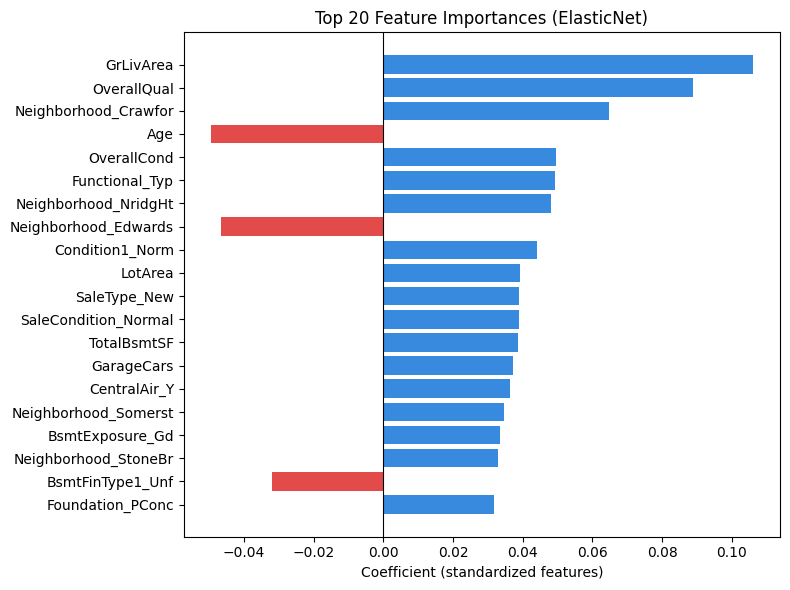

In [112]:
import matplotlib.pyplot as plt

def plot_feature_importance(result, top_n=20):
    coefs = result['coefficients']  # already nonzero, sorted by abs value (descending)
    top_coefs = coefs.head(top_n).iloc[::-1]  # reverse for horizontal bar chart (largest on top)

    plt.figure(figsize=(8, max(4, len(top_coefs) * 0.3)))
    colors = ['#378ADD' if v > 0 else '#E24B4A' for v in top_coefs.values]
    plt.barh(top_coefs.index, top_coefs.values, color=colors)
    plt.axvline(0, color='black', linewidth=0.8)
    plt.xlabel("Coefficient (standardized features)")
    plt.title(f"Top {len(top_coefs)} Feature Importances (ElasticNet)")
    plt.tight_layout()
    plt.show()


# --- usage ---
plot_feature_importance(result, top_n=20)

In [115]:
def predict_test_set(test_df, result, num_cols, cat_cols):
    scaler = result['scaler']
    X_columns = result['X_columns']
    model = result['prod_model']

    # --- encode test set the same way as train ---
    dummies = pd.get_dummies(test_df[cat_cols], drop_first=True)
    num_scaled = pd.DataFrame(scaler.transform(test_df[num_cols]), columns=num_cols, index=test_df.index)

    X_test = pd.concat([num_scaled, dummies], axis=1)
    X_test = X_test.reindex(columns=X_columns, fill_value=0)  # align to train's dummy columns
    X_test = X_test.astype(float)

    return model.predict(X_test)

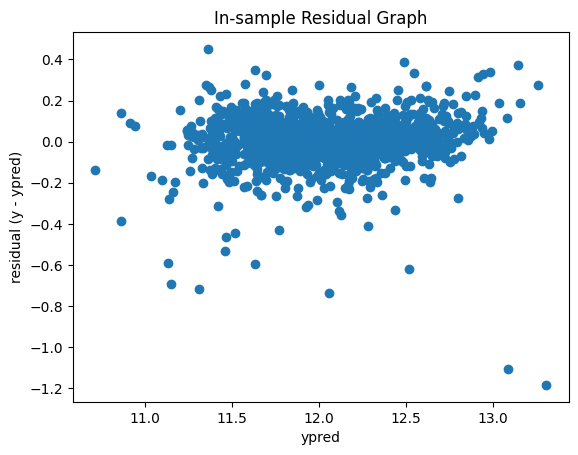

In [ ]:
# in-sample residual graph -> observe that it does not have a funnel shape / trend

train_preds = predict_test_set(train_df, result, num_cols, cat_cols)

plt.scatter(train_preds, train_df["SalePrice"] - train_preds)

plt.xlabel("ypred")
plt.ylabel("residual (y - ypred)")
plt.title("In-sample Residual Graph")
plt.show()

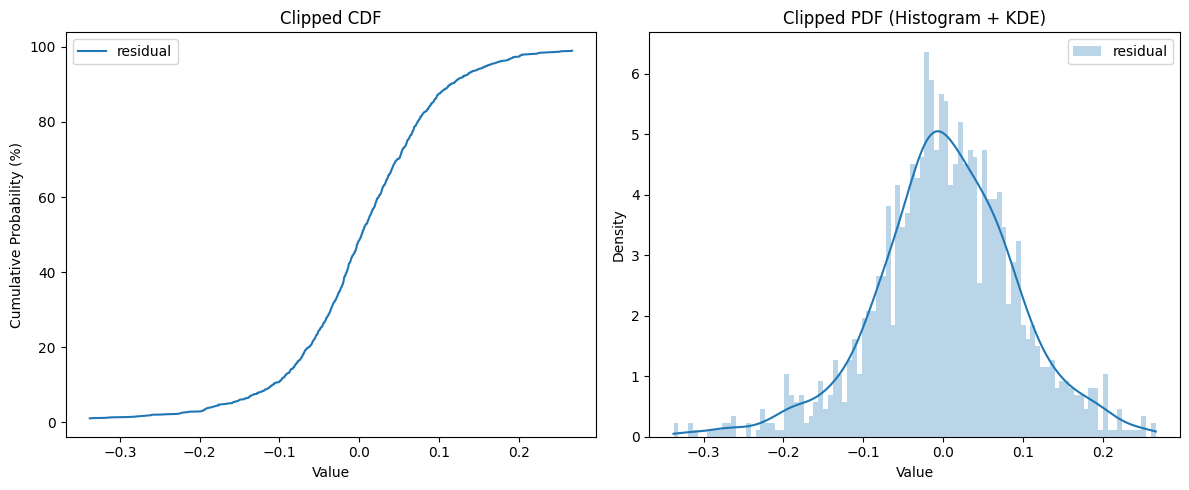

In [ ]:
# log-residual looks normal

plot_clipped_CDF_and_PDF({"residual": train_df["SalePrice"] - train_preds})

In [121]:
# estimate smearing factor
# this method assumes normality of log-residuals and homoscedasticity (constant sigma2)
sigma2 = np.var(train_df["SalePrice"] - train_preds)
smearing_factor = sigma2 / 2

smearing_factor

np.float64(0.00668432934766891)

In [122]:
test_preds = predict_test_set(test_df, result, num_cols, cat_cols)

In [123]:
test_preds

array([11.6197058 , 11.9712366 , 12.11414173, ..., 12.04913588,
       11.70012752, 12.36642165], shape=(1459,))

In [126]:
# apply exponential + smearing factor to get back original price

final_predictions = np.exp(test_preds + smearing_factor)

final_predictions

array([112015.23066512, 159200.69720646, 183657.16379822, ...,
       172098.14573217, 121395.83489292, 236358.73168335], shape=(1459,))

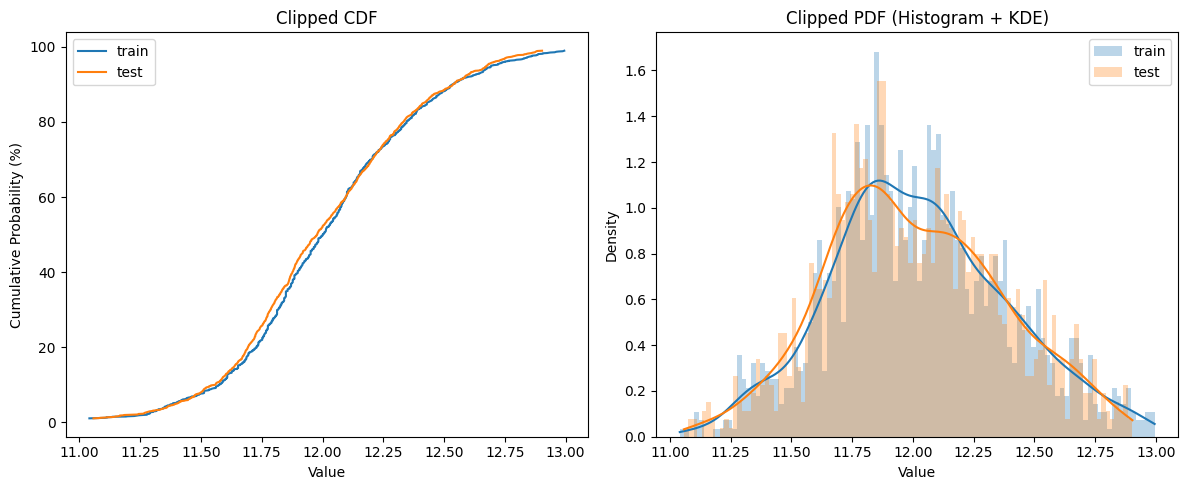

In [125]:
plot_clipped_CDF_and_PDF({"train": train_df["SalePrice"].to_numpy(), "test": test_preds})